In [1]:
from shares.middlewares.service_options_handler import OptionHandler
from shares.middlewares.service_auto_ml_handler import AutoMlHandler
from shares.modules.log import Log
from shares.modules.redis import r as redis_single
from shares.modules.minio import MinioModule
from shares.modules.tensorflow_module import TensorflowModule
from shares.modules.sklearn_module import SklearnModule
from shares.dao.runnable_services_dao import runnableServicesDao
from shares.dao.upbit_transaction_dao import UpbitTransactionDao
from shares.functions.common_function import get_years_between_str, split_date_range_by_year
from shares.functions.common_function import generate_micro_date

from apscheduler.schedulers.blocking import BlockingScheduler

import mlflow

import pandas as pd
import datetime
import time

import os
import inspect

2025-08-04 16:29:20.834678: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-08-04 16:29:20.834797: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [2]:

class CvAiTrainerS1Gen02(AutoMlHandler, OptionHandler):
    """
    Service group : AiTrainer
    Service no : 1
    Generation : 02 
    Product Name : Queen bee
    
    Role : 
    1. KRW-BTC 2일 뒤 정가대비 예측 모델 생성
    """
    slack_post_prefix = ":bee: Queen Bee."
    
    def __init__(self, seq):
        self.log = Log(os.path.basename("jup")).get_logger()
        self.redis = redis_single
        self.minio = MinioModule()
        self.tensorflow_module = TensorflowModule()
        self.sklearn_module = SklearnModule()
        self.runnable_services_dao = runnableServicesDao()
        self.upbit_transaction_dao = UpbitTransactionDao()
         
        # 옵션 오토 로드
        self.scheduler_start_day = None
        self.scheduler_start_hour = None
        self.scheduler_start_min = None
        self.auto_back_test = None
        self.auto_back_test_seq = None
        self.auto_ml_path = None
        self.ticker = None
        self.dataset_load_term = None
        self.dataset_table_prefix = None
        self.load_options(seq)
        
        self.seq = seq
        self.model_path = ""


    def run(self):
        try:
            # 데이터 조회
            df = self.get_dataframe()
            self._initialize(df, self.auto_ml_path)
            self.load_auto_ml()
            self.apply_dervied_params()
            self.apply_preprocess()
            return self.df
            
        except Exception as e:
            self.log.info(f"class : {self.__class__.__name__}, method : {inspect.currentframe().f_code.co_name}, error : {str(e)}")
            
    def get_dataframe(self):
        
        # --- 데이터 셋팅
        now_date = str(datetime.datetime.now())[0:19]
        n_days_ago = str(datetime.datetime.now() - datetime.timedelta(days=self.dataset_load_term))[0:19]   
        self.year_list = get_years_between_str(n_days_ago, now_date)  # 대상연도
        self.splited_year_dict = split_date_range_by_year(n_days_ago, now_date) 
        
        # --- 연단위 테이블 생성 (있으면 pass)
        self.upbit_transaction_dao.create_yearly_table(self.year_list)
    
        # --- 데이터 조회
        upbit_transactions_list = []
        for year in self.year_list:
            
            table_name = f"{self.dataset_table_prefix}_{year}"
            
            splited_year = self.splited_year_dict[year]
            start = splited_year[0]
            end = splited_year[1]
            
            upbit_transactions = self.upbit_transaction_dao.get_upbit_transactions_between(table_name, self.ticker, start, end)
            upbit_transactions_list += upbit_transactions
        
        if len(upbit_transactions_list) == 0:
            self.log.info(f'no dataset found')
            raise 
        
        # --- 데이터프레임으로 변환
        df = pd.DataFrame(upbit_transactions_list)
        
        return df 
    

In [3]:
cv = CvAiTrainerS1Gen02(11)

In [4]:
df = cv.run()

/apps/scheduler/auto_ml/service/cv_ai_trainer_s1_gen02/v1/preprocess.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.df[col] = pd.to_numeric(self.df[col].astype(str).str.replace(",", "").str.strip(), errors='raise')
/apps/scheduler/auto_ml/service/cv_ai_trainer_s1_gen02/v1/preprocess.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.df[cols] = StandardScaler().fit_transform(self.df[cols])


In [5]:
df = cv.get_df()

In [6]:
features = cv.get_features()

In [7]:
targets = cv.get_targets()

In [8]:
df_f = df[features]

# 1. features가 실제 컬럼에 있는지 확인
valid_features = [col for col in features if col in df_f.columns]
print("유효한 feature 수:", len(valid_features))
print(valid_features)

유효한 feature 수: 92
['timestamp', 'weekday', 'open', 'high', 'low', 'close', 'volume', 'volume_ma5', 'volume_ma20', 'volume_ratio', 'obv', 'vwap', 'volume_volatility', 'volume_spike', 'rsi', 'macd', 'macd_signal', 'bollinger_partition', 'bollinger_partition_prev', 'atr', 'cci', 'stochastic_k', 'stochastic_d', 'roc', 'momentum', 'ema_cross_up', 'cdl2crows', 'cdl3blackcrows', 'cdl3inside', 'cdl3linestrike', 'cdl3outside', 'cdl3starsinsouth', 'cdl3whitesoldiers', 'cdlabandonedbaby', 'cdladvanceblock', 'cdlbelthold', 'cdlbreakaway', 'cdlclosingmarubozu', 'cdlconcealbabyswall', 'cdlcounterattack', 'cdldarkcloudcover', 'cdldoji', 'cdldojistar', 'cdldragonflydoji', 'cdlengulfing', 'cdleveningdojistar', 'cdleveningstar', 'cdlgapsidesidewhite', 'cdlgravestonedoji', 'cdlhammer', 'cdlhangingman', 'cdlharami', 'cdlharamicross', 'cdlhighwave', 'cdlhikkake', 'cdlhikkakemod', 'cdlhomingpigeon', 'cdlidentical3crows', 'cdlinneck', 'cdlinvertedhammer', 'cdlkicking', 'cdlkickingbylength', 'cdlladderbottom'

In [9]:
# 상관관계 분석 (Correlation Analysis)
import numpy as np

def get_top_correlations(corr_matrix, n=20):
    # 삼각행렬 상부만 추출하여 중복 제거
    corr_matrix_no_self = corr_matrix.where(~np.eye(corr_matrix.shape[0], dtype=bool))
    upper = corr_matrix_no_self.where(np.triu(np.ones(corr_matrix_no_self.shape), k=1).astype(bool))
    
    top = upper.abs().stack().sort_values(ascending=False).head(n)
    return top
    
corr = df_f.corr()
top_correlations = get_top_correlations(corr, n=50)
print(top_correlations)

cdl3blackcrows            cdl3starsinsouth            1.000000
close_open_ratio          price_change_ratio          1.000000
high_low_ratio            daily_range                 0.999998
high                      close                       0.999669
open                      low                         0.999655
                          high                        0.999639
low                       close                       0.999633
high                      low                         0.999471
open                      close                       0.999322
                          vwap                        0.988020
low                       vwap                        0.987793
high                      vwap                        0.987790
close                     vwap                        0.987513
rolling_volatility        volatility_1h               0.964035
macd                      macd_signal                 0.950147
bollinger_partition       cci                         0

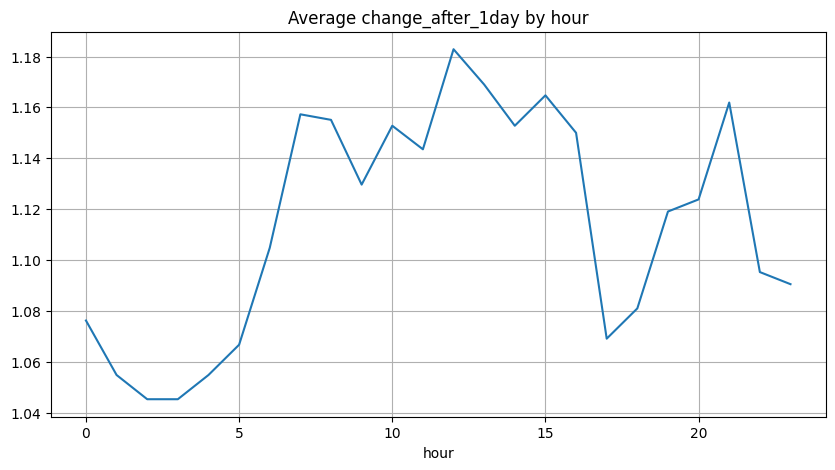

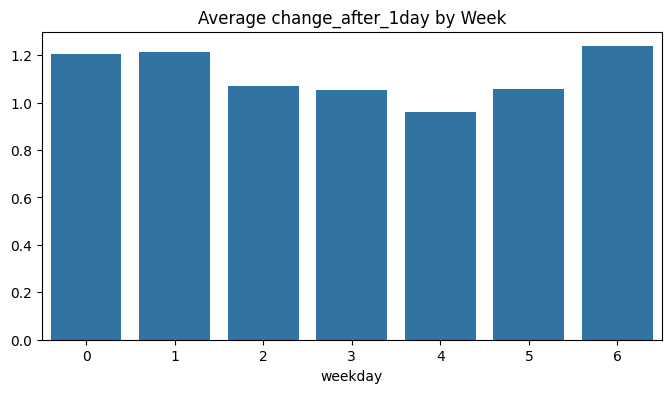

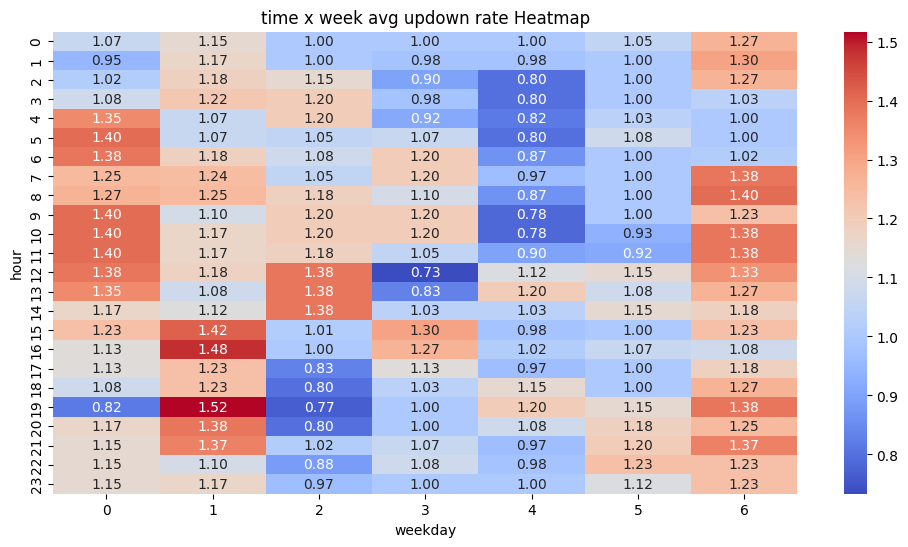

In [10]:
# 시간 특이점 검사
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt


# 1. timestamp 컬럼 datetime 변환 (unit='s' 또는 'ms' 꼭 지정)
df['timestamp'] = pd.to_datetime(df['timestamp'], unit='s')

# 2. 시간대 추출 (예: 시(hour))
df['hour'] = df['timestamp'].dt.hour

# 3) 시간대별 평균 등락률 (numeric 타입일 경우)
hourly_mean_change = df.groupby('hour')['change_after_1day'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=hourly_mean_change.index, y=hourly_mean_change.values)
plt.title('Average change_after_1day by hour')
plt.grid(True)
plt.show()

# 4) 요일별 등락률 평균
weekday_mean_change = df.groupby('weekday')['change_after_1day'].mean()

plt.figure(figsize=(8, 4))
sns.barplot(x=weekday_mean_change.index, y=weekday_mean_change.values)
plt.title('Average change_after_1day by Week')
plt.show()

# 5) 시간대별 x 요일별 heatmap 시각화 (pivot table)
pivot = df.pivot_table(values='change_after_1day', index='hour', columns='weekday', aggfunc='mean')

plt.figure(figsize=(12, 6))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="coolwarm")
plt.title('time x week avg updown rate Heatmap')
plt.show()


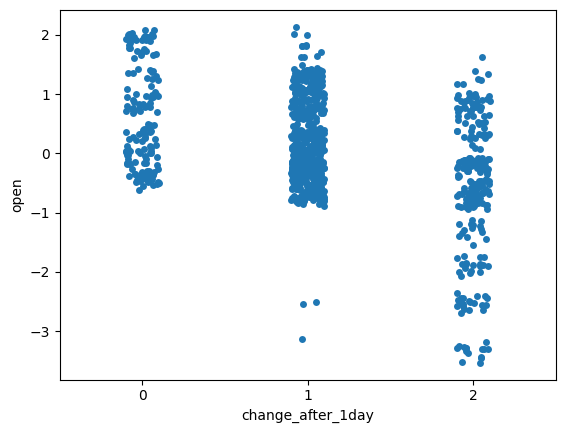

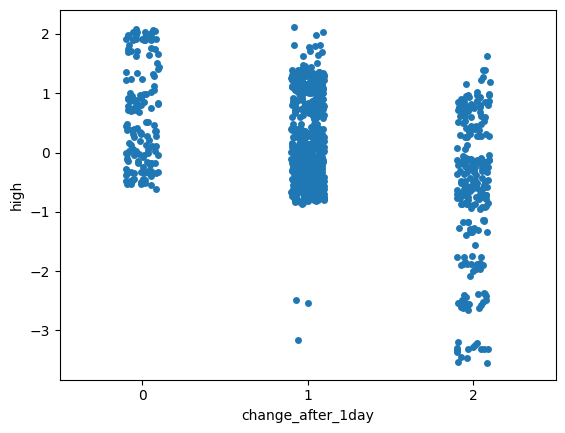

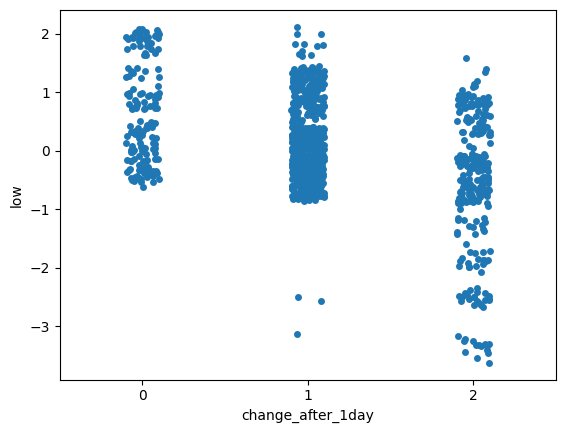

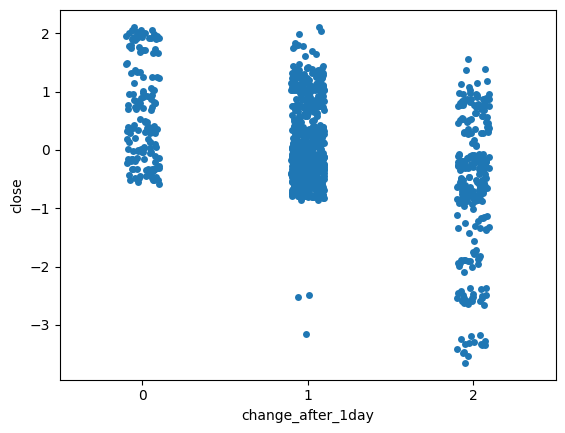

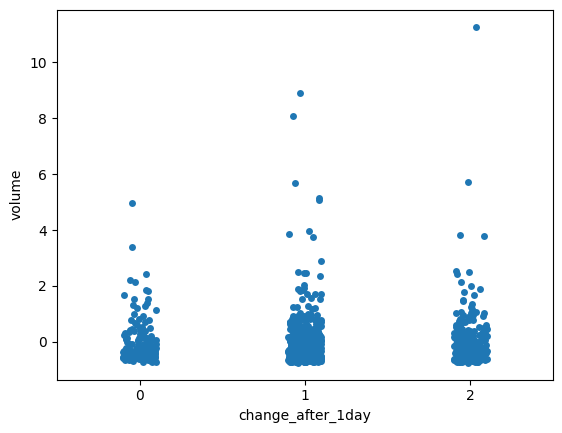

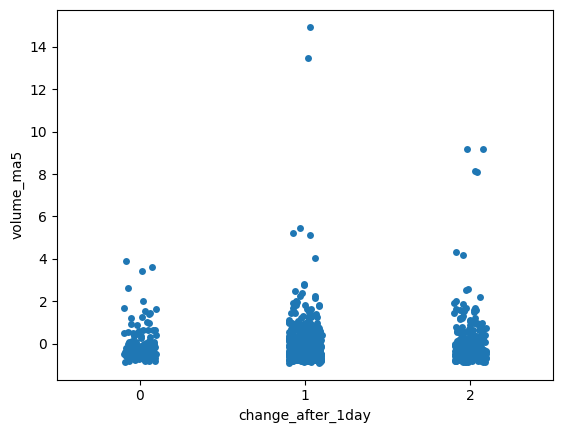

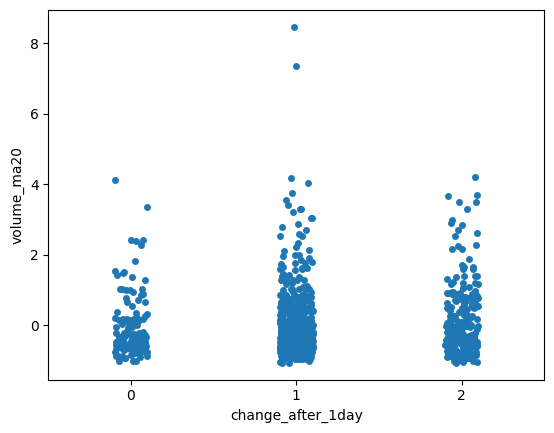

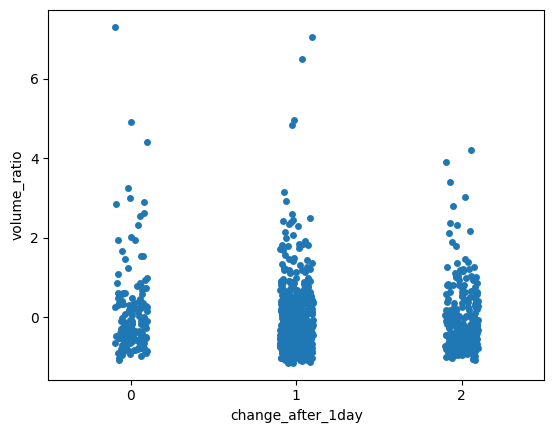

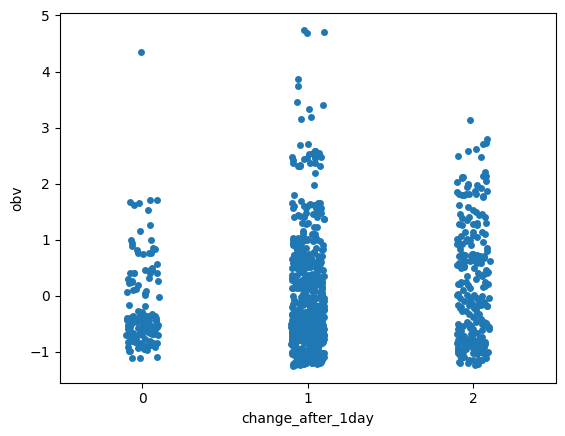

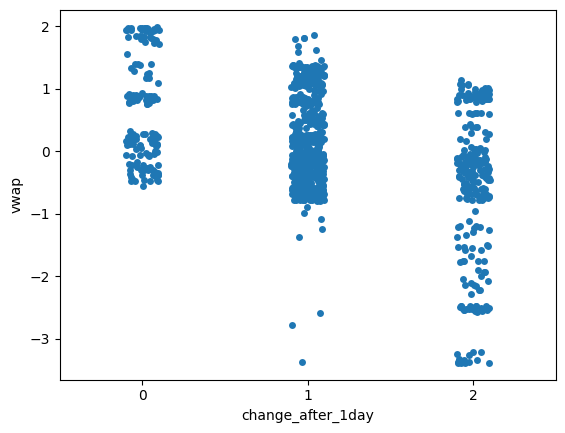

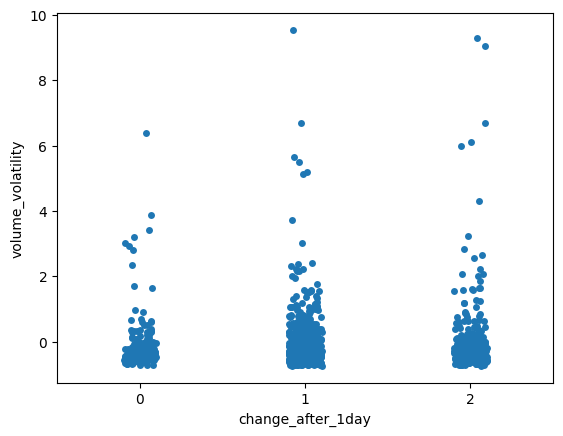

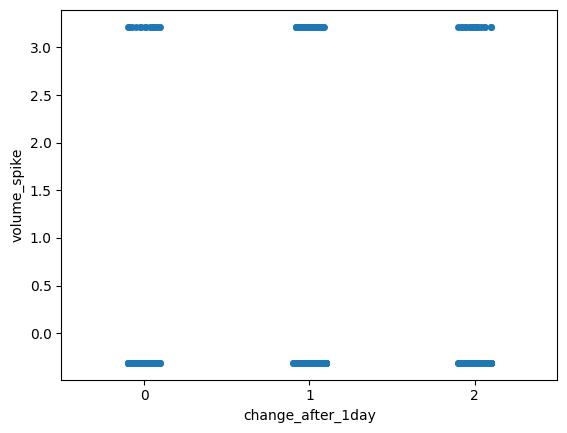

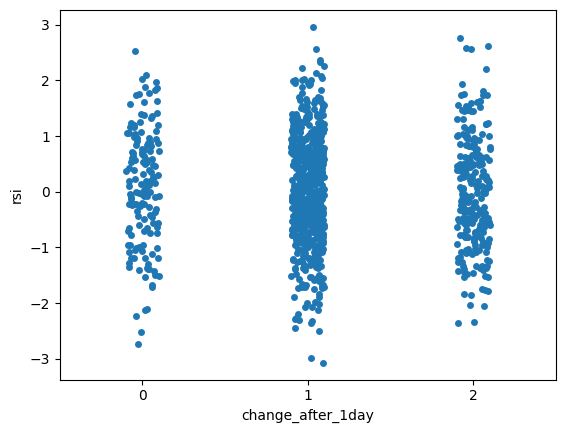

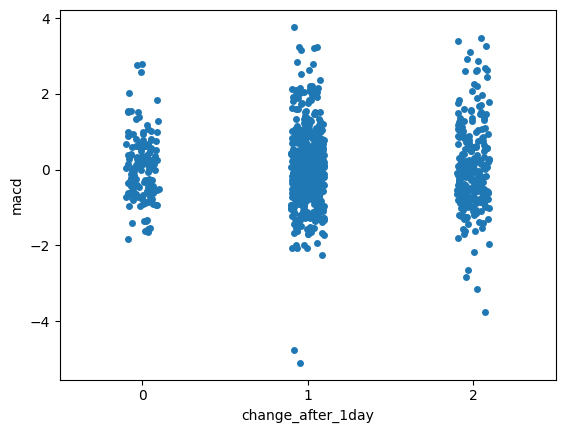

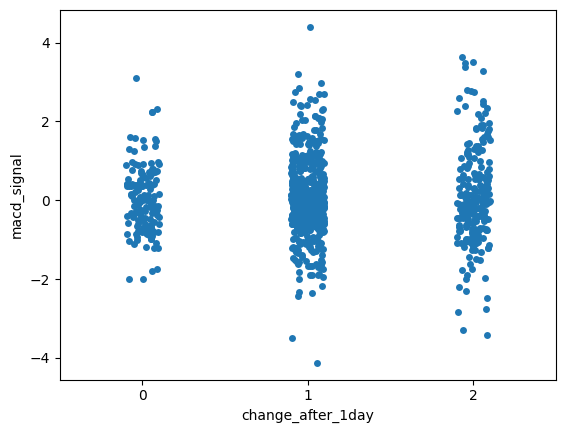

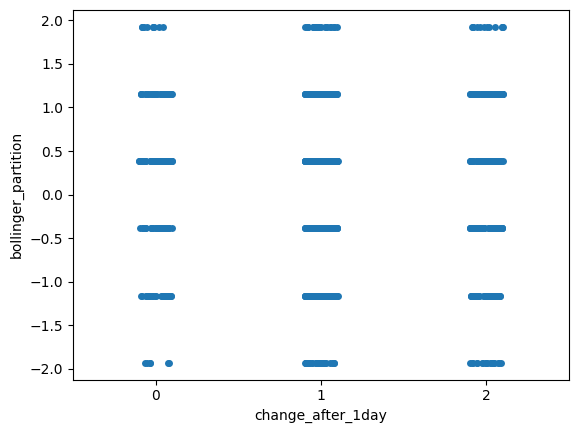

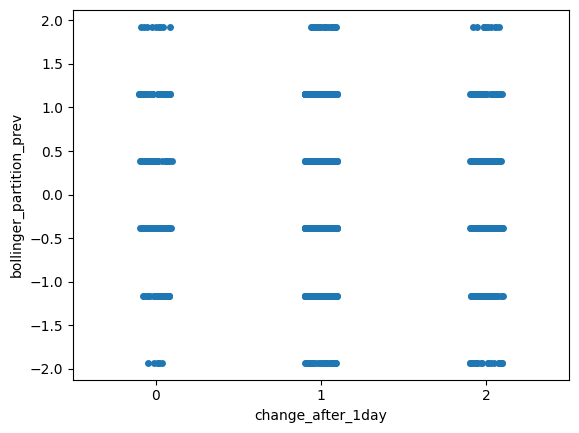

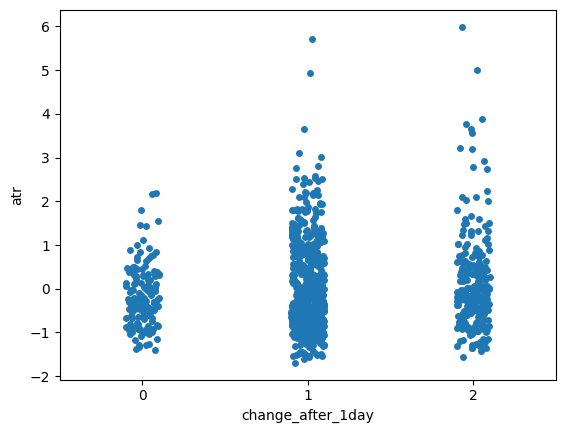

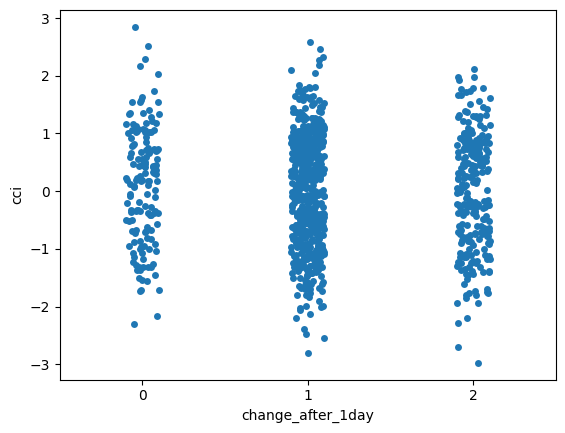

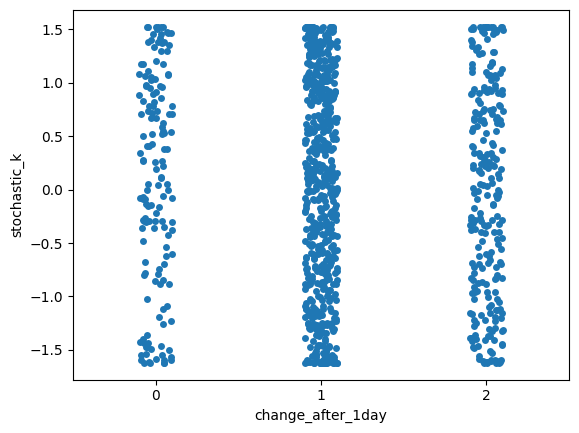

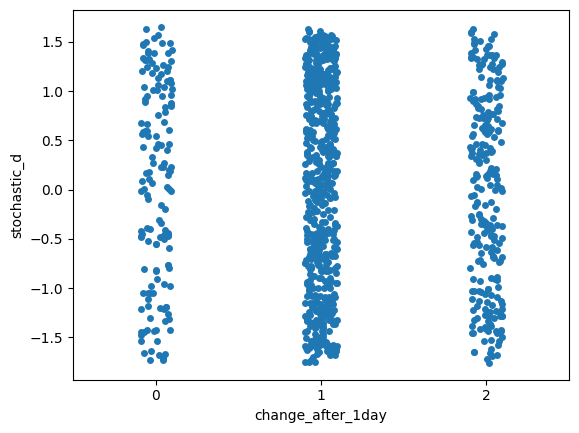

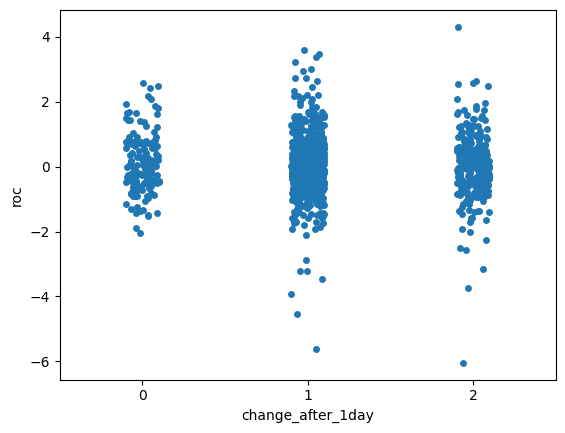

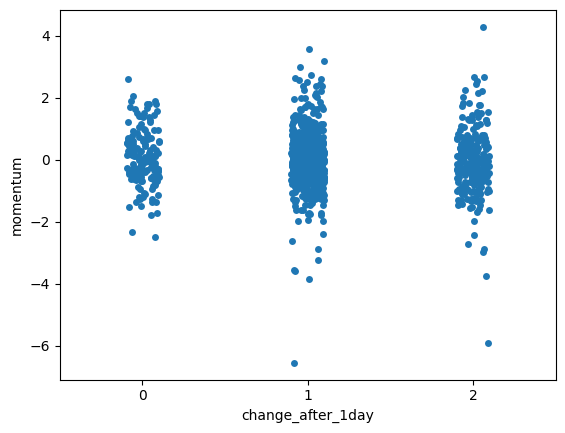

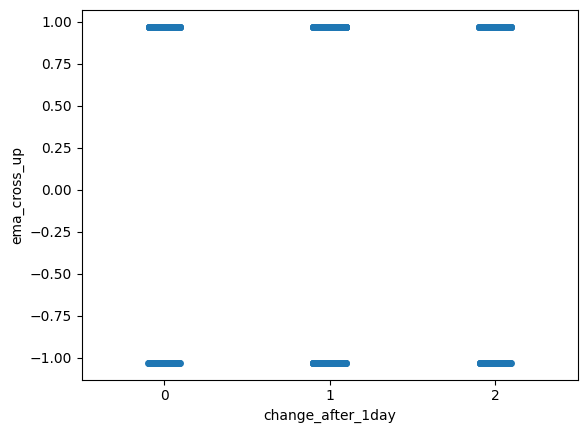

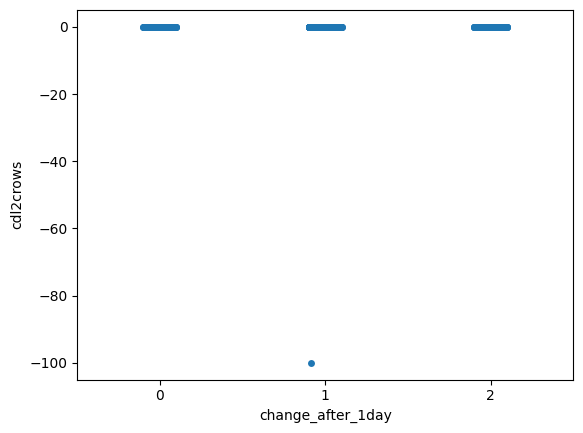

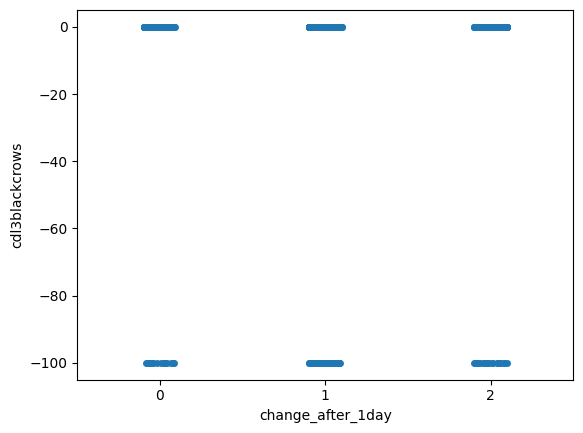

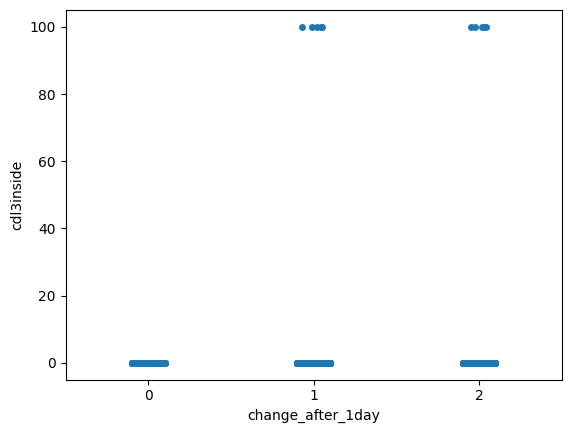

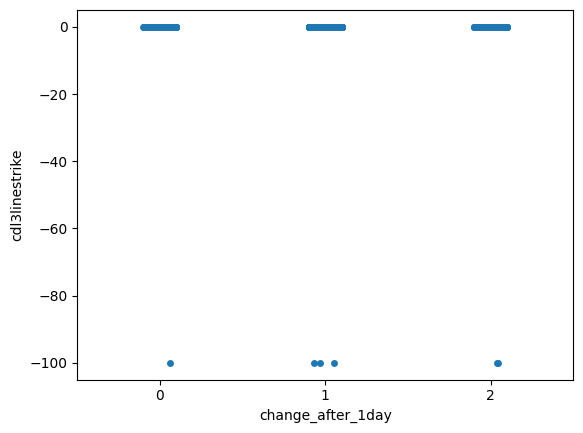

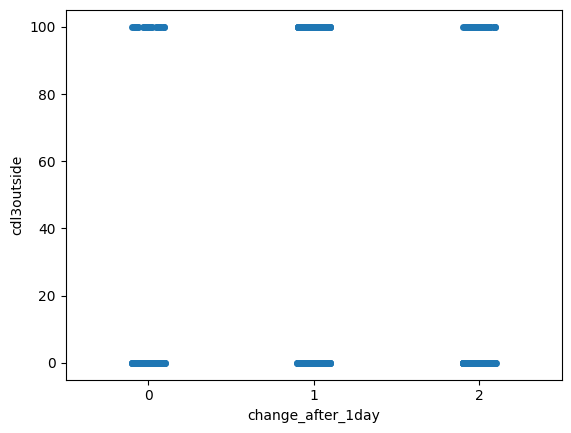

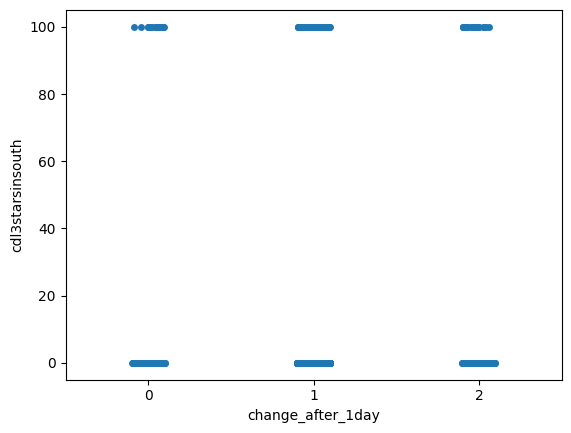

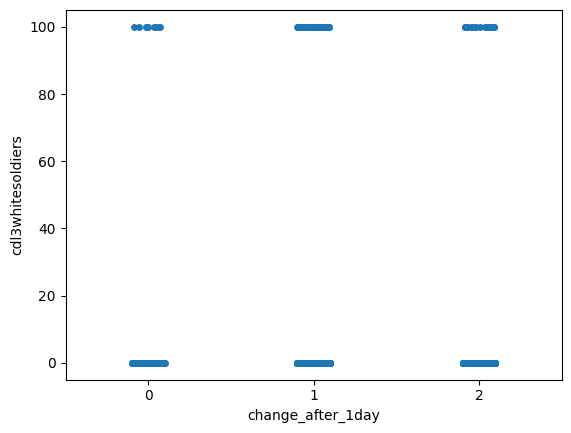

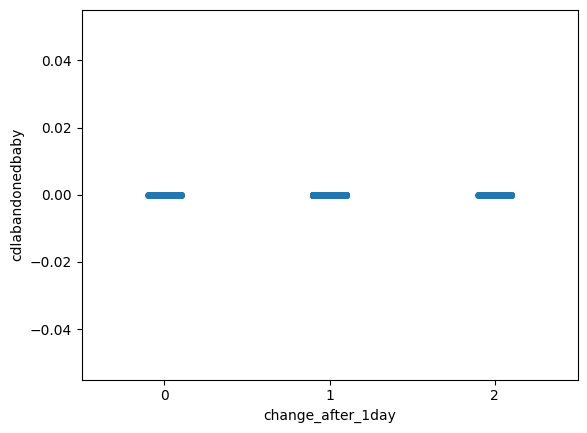

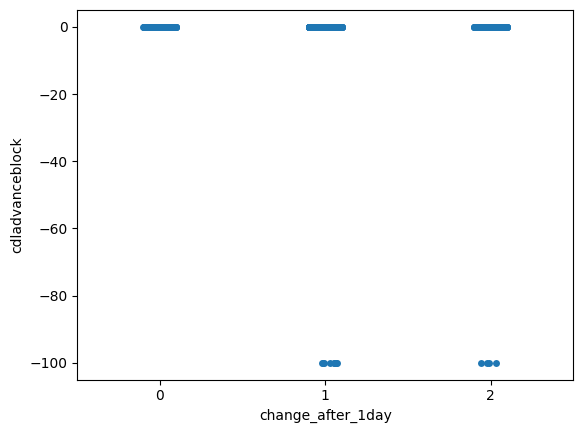

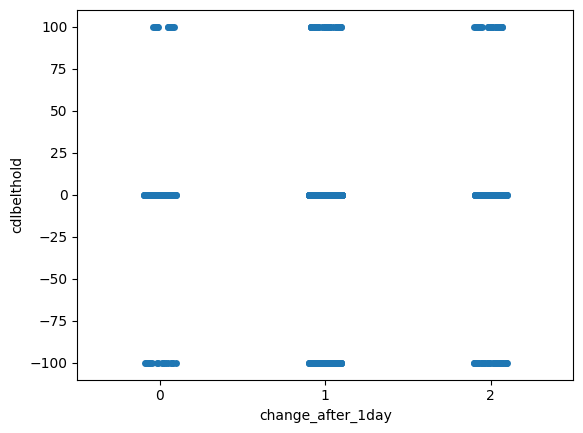

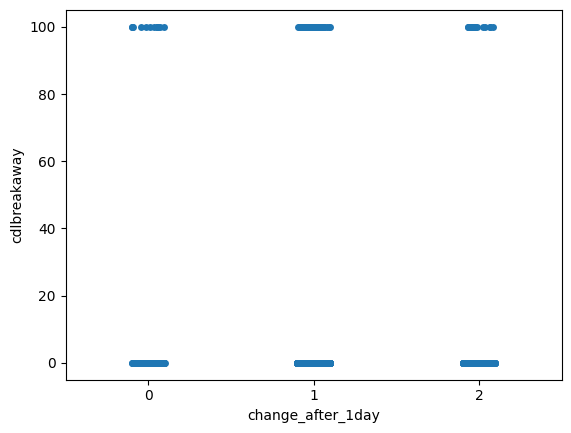

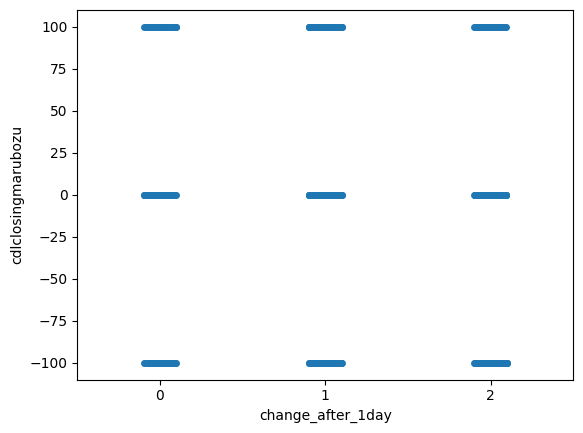

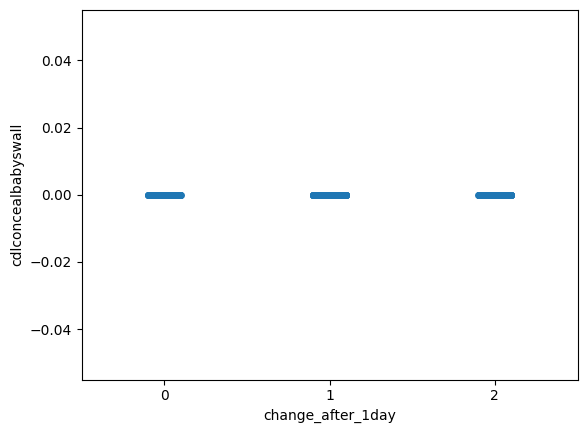

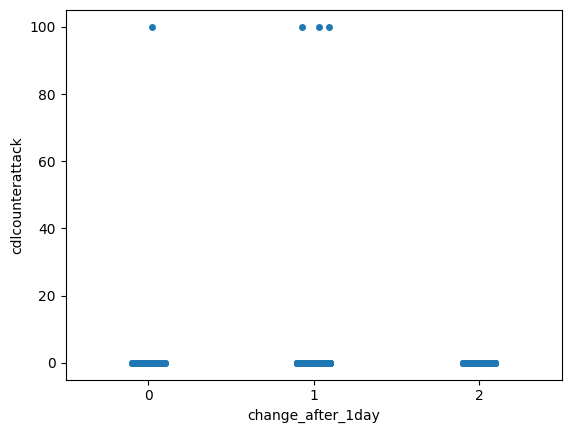

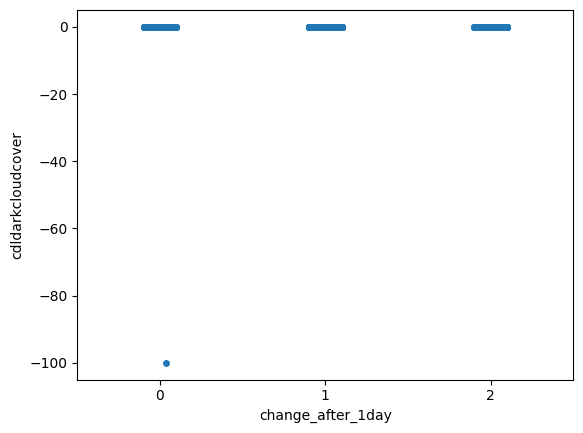

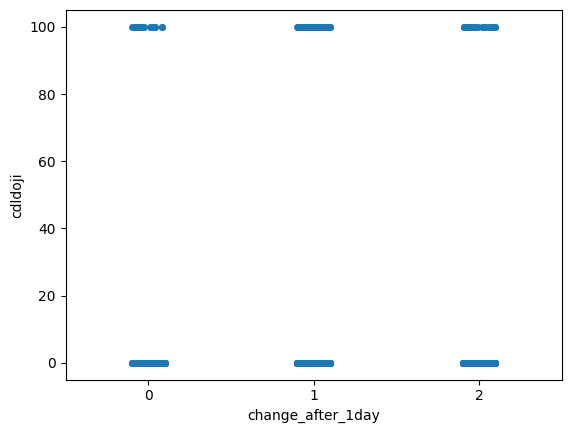

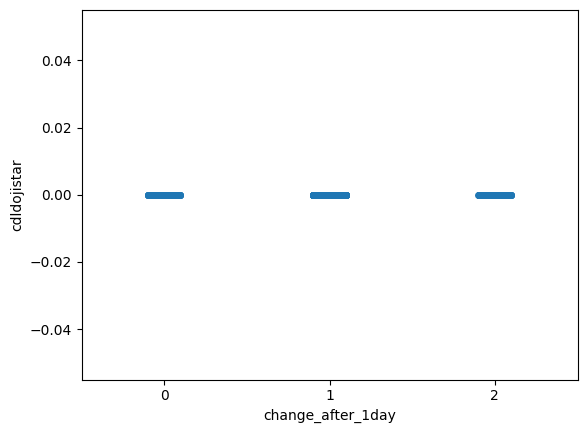

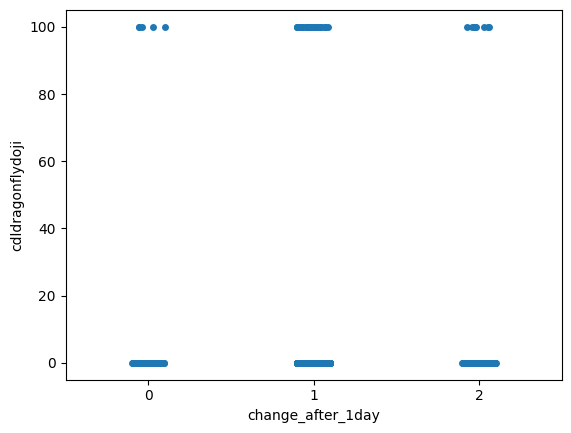

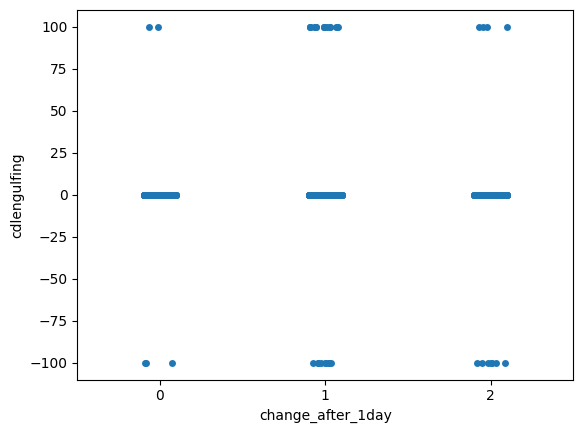

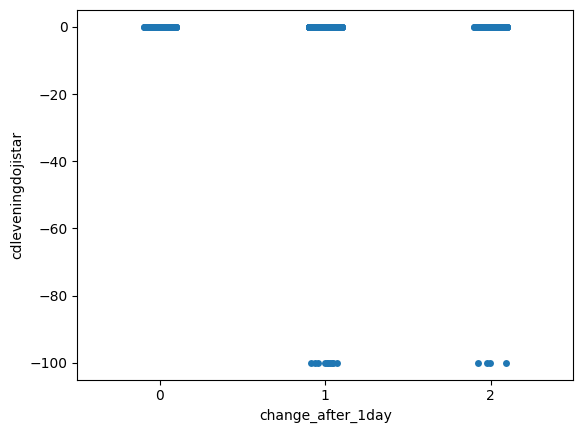

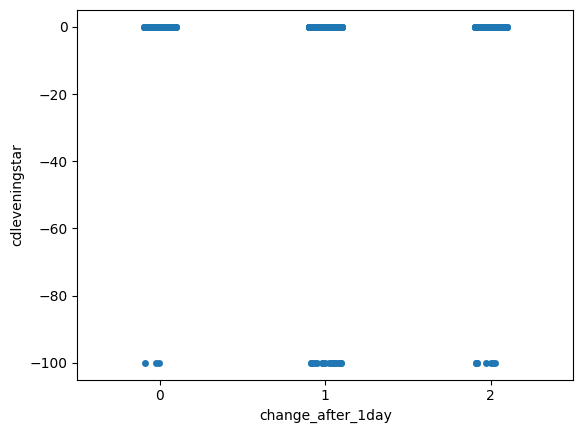

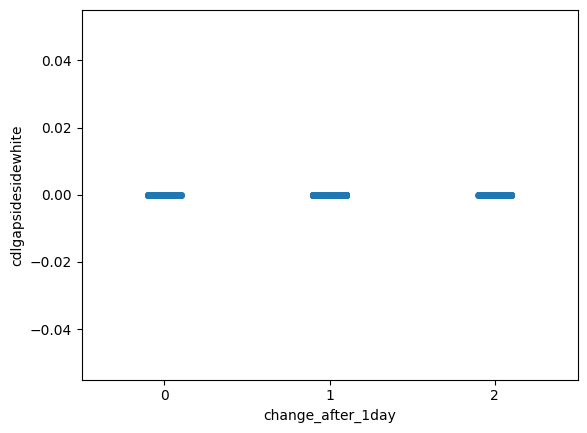

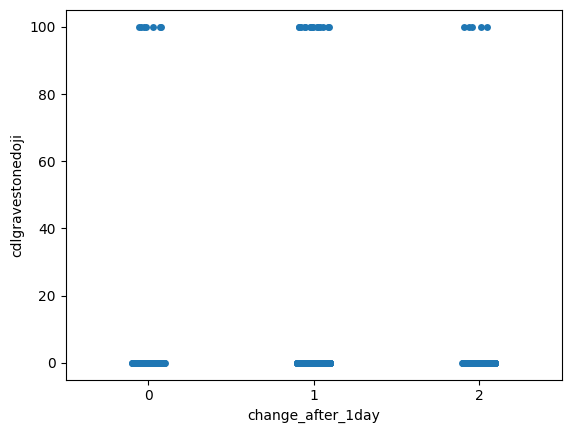

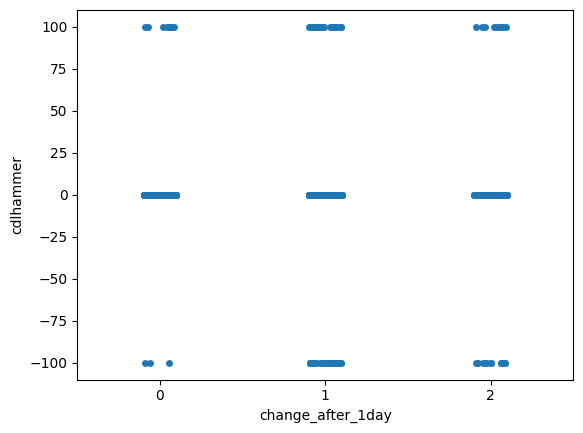

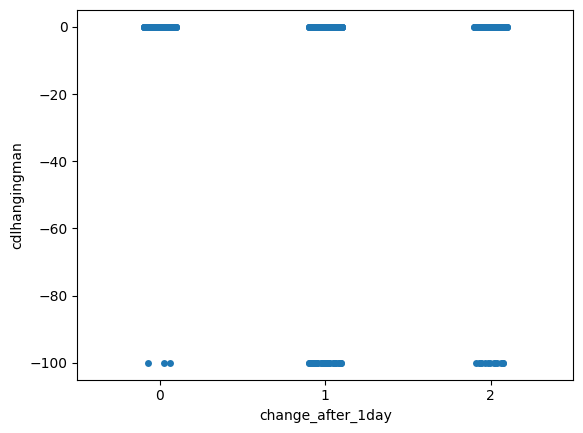

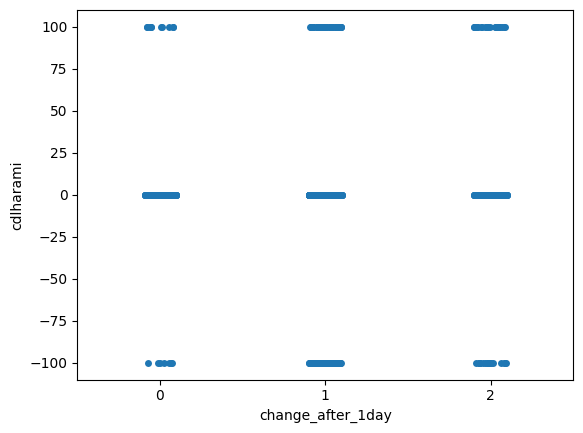

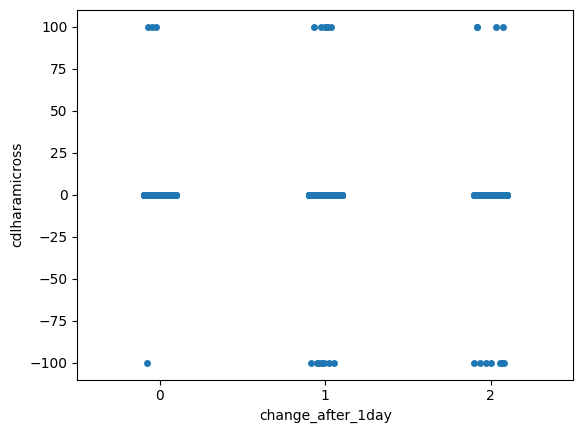

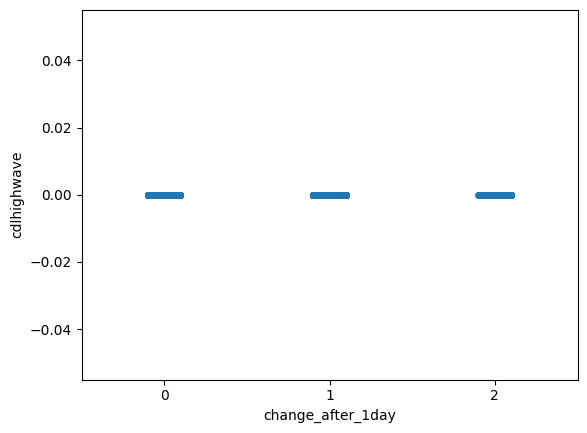

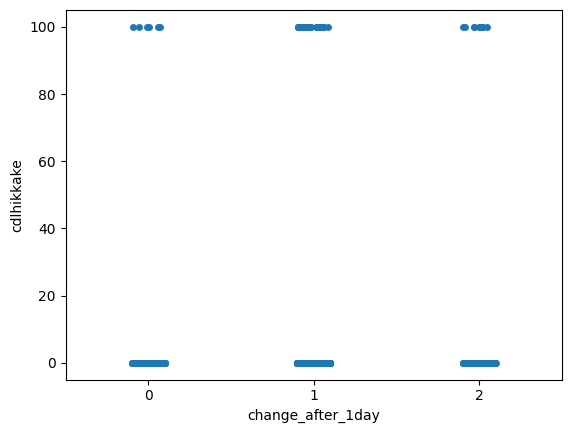

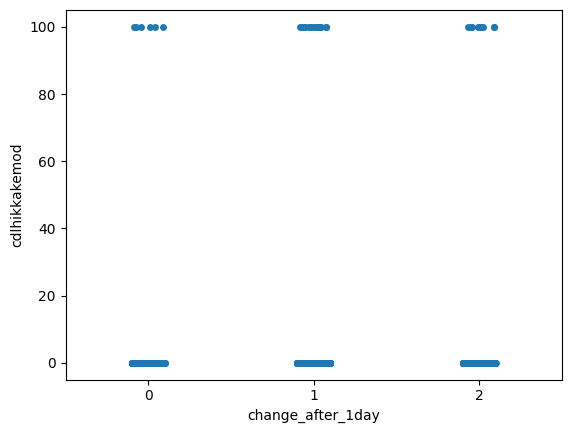

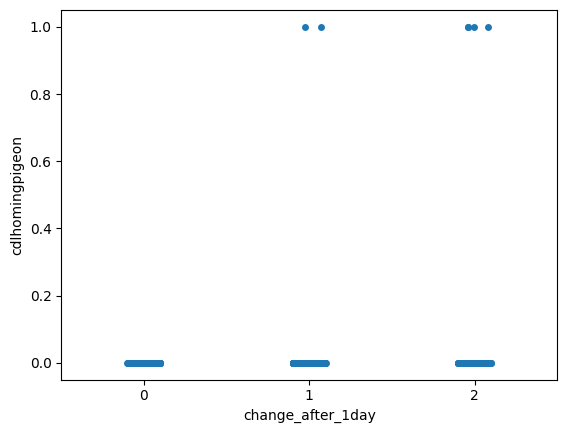

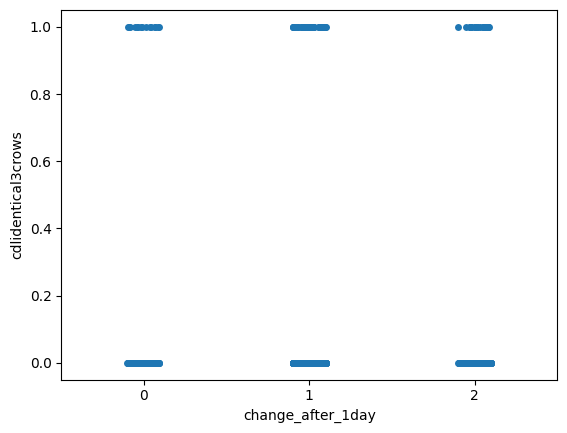

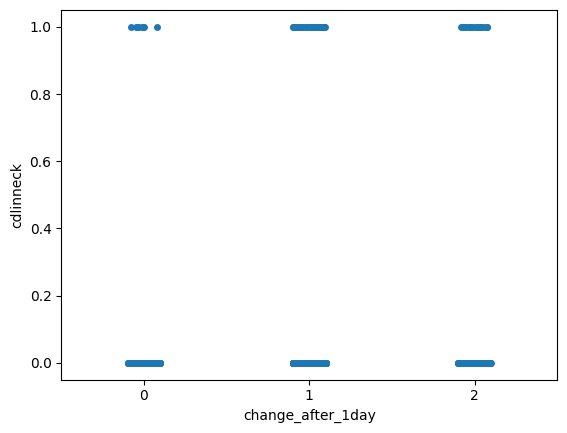

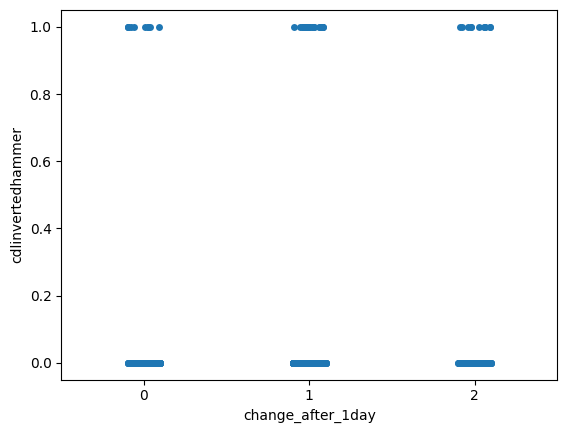

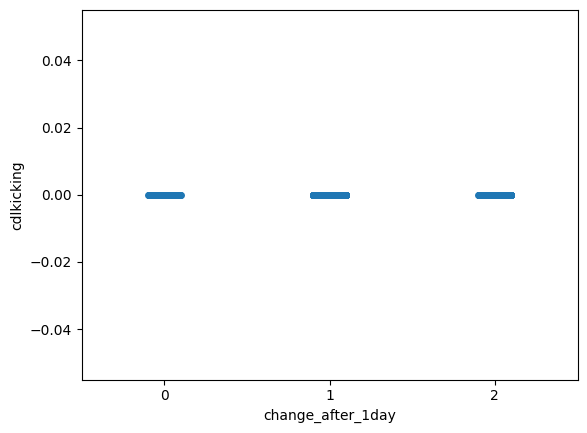

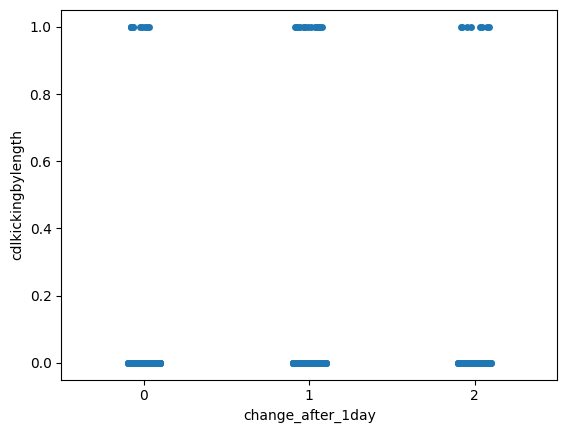

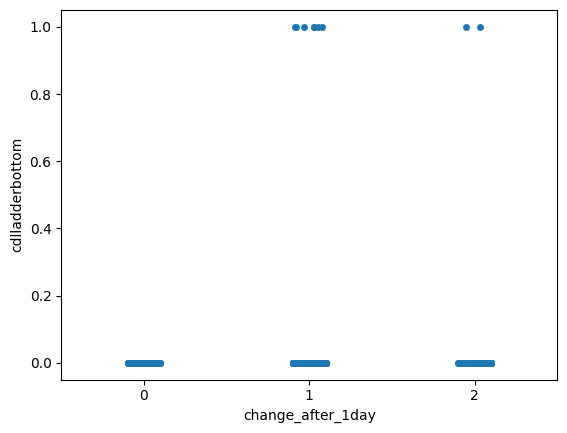

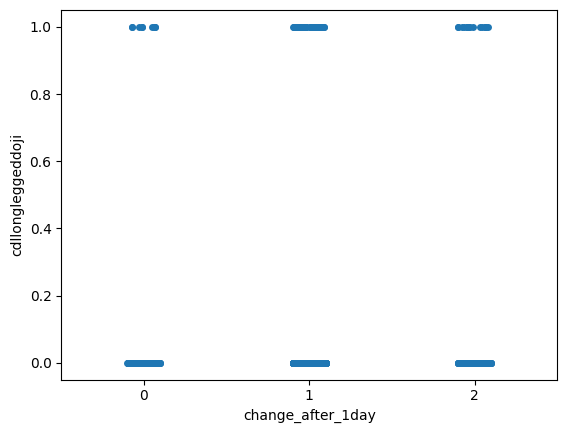

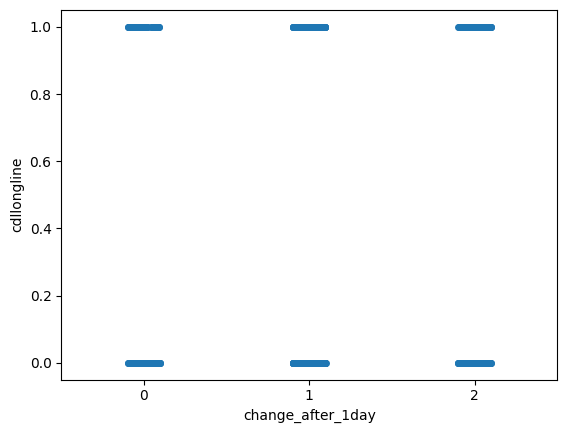

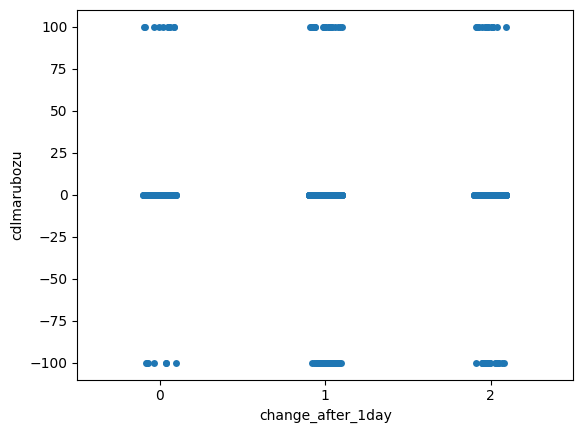

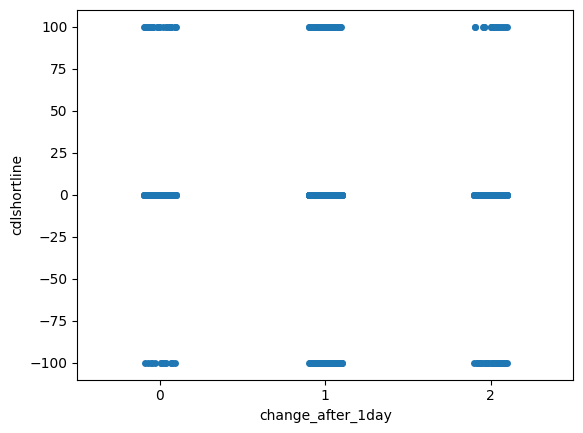

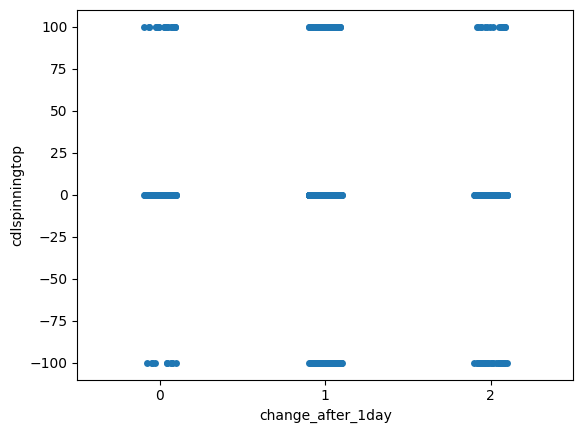

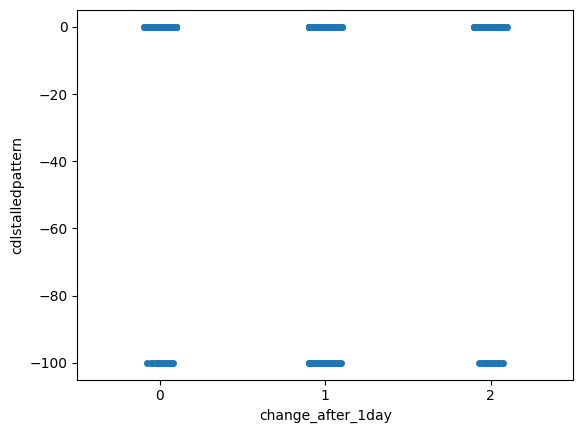

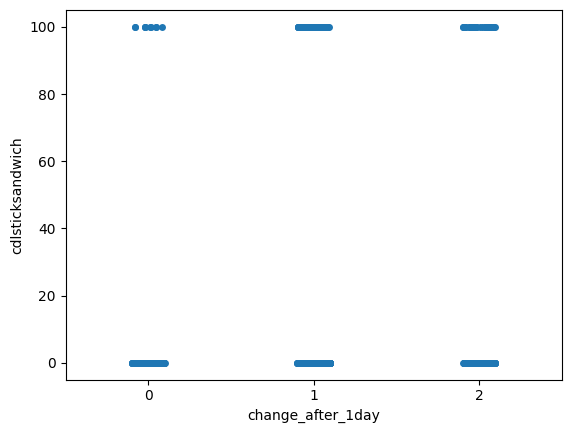

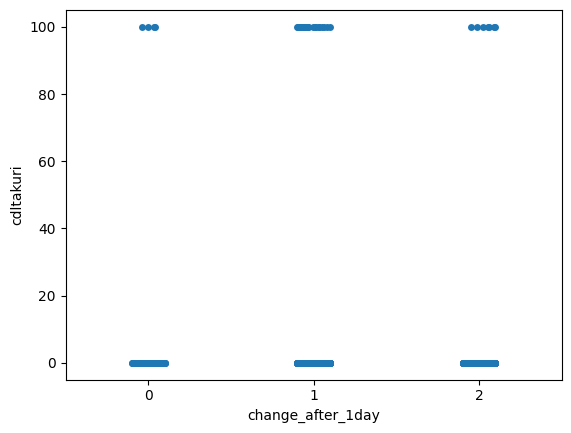

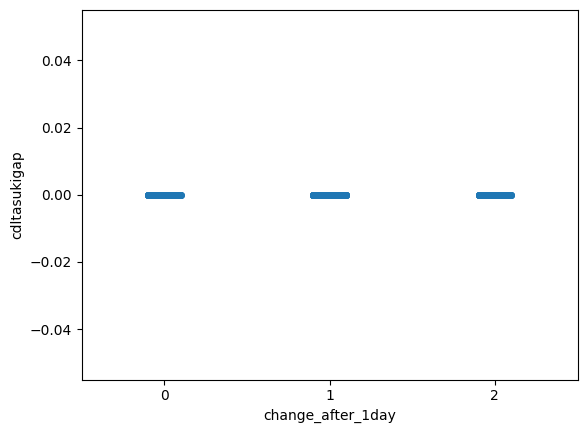

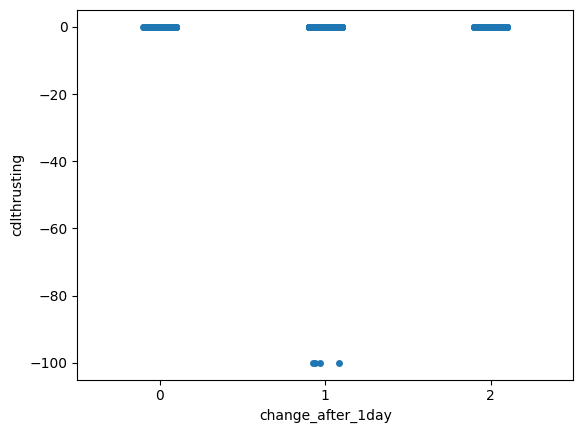

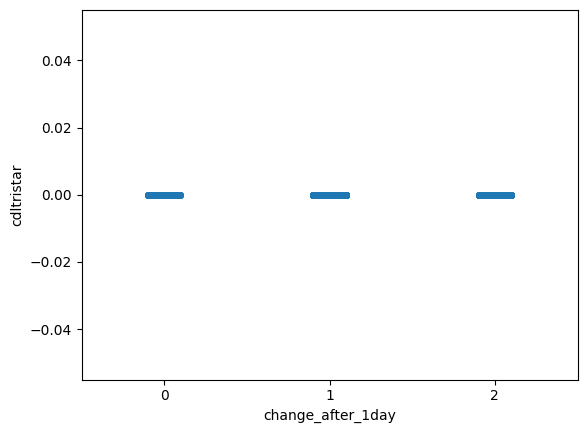

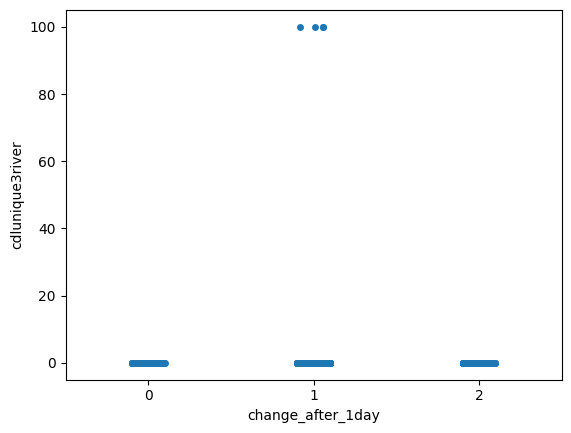

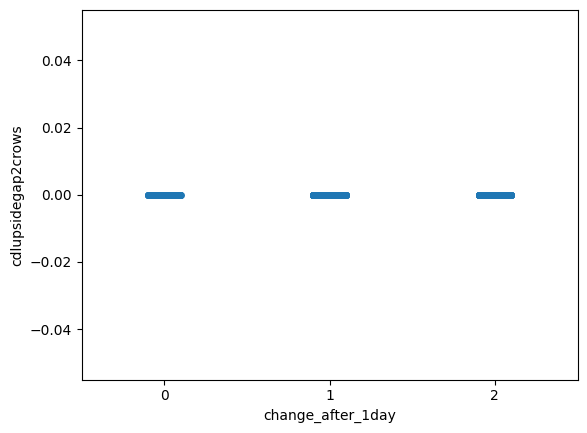

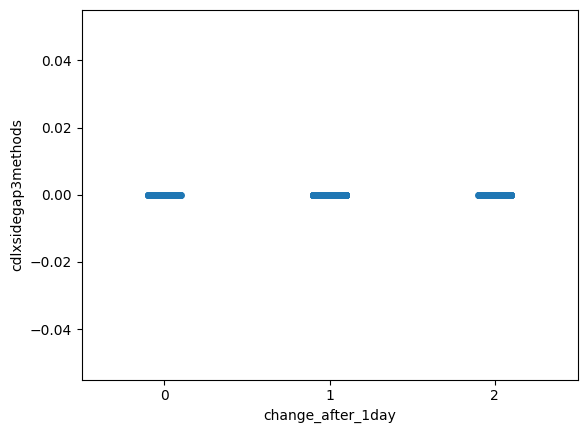

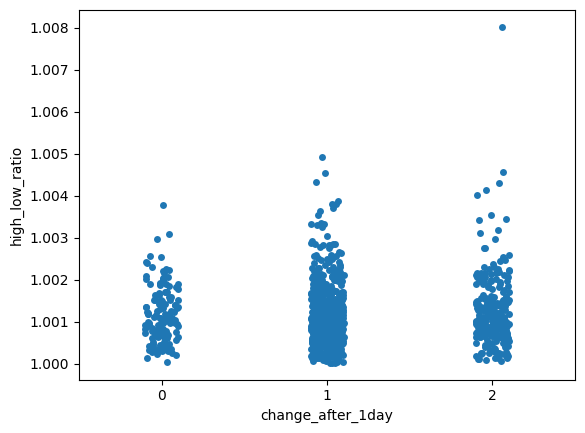

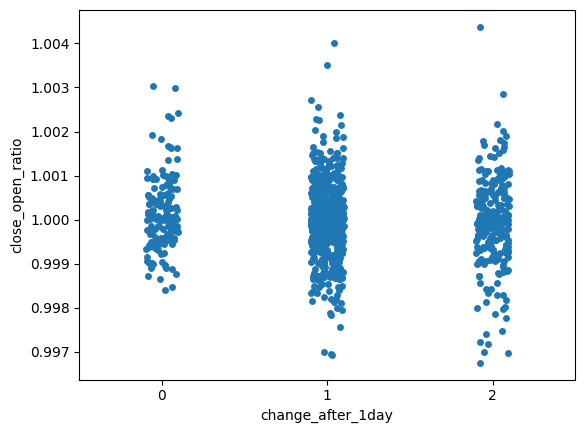

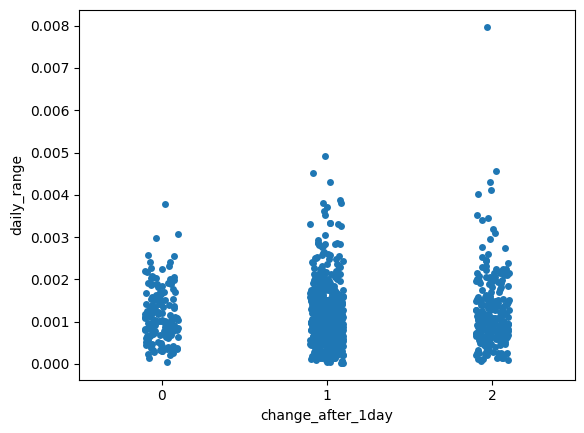

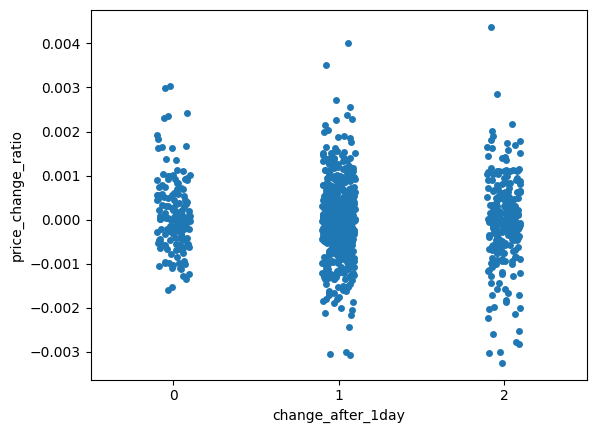

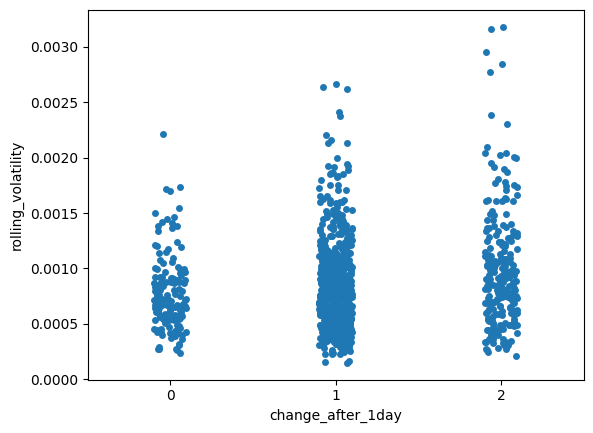

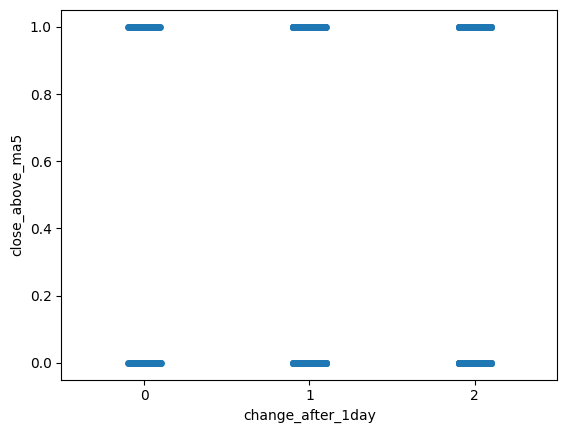

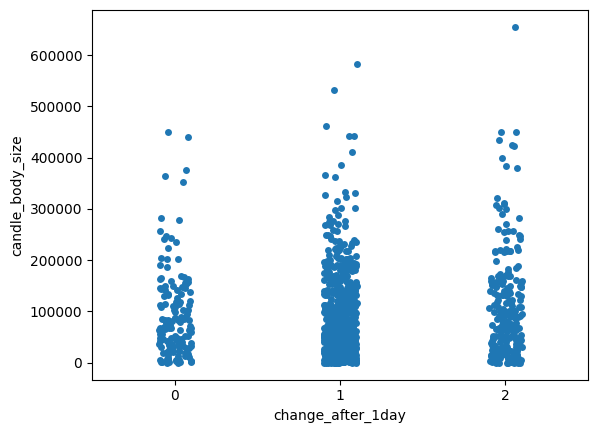

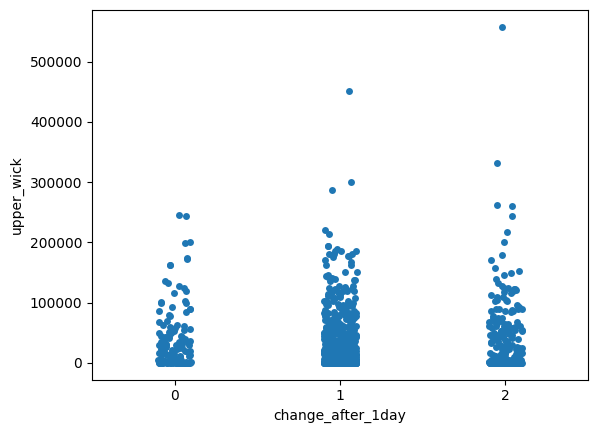

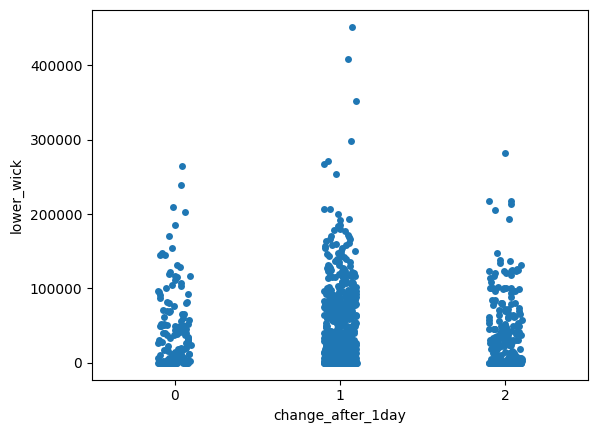

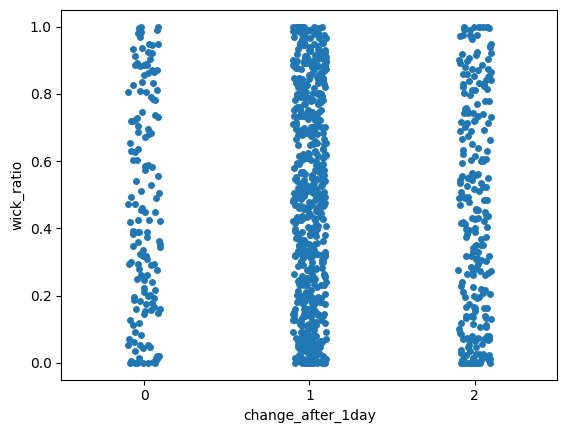

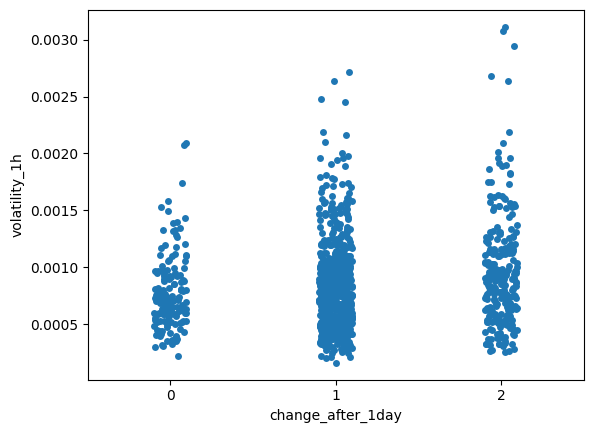

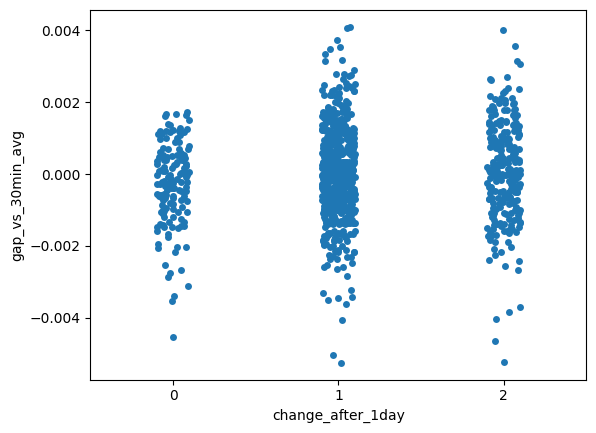

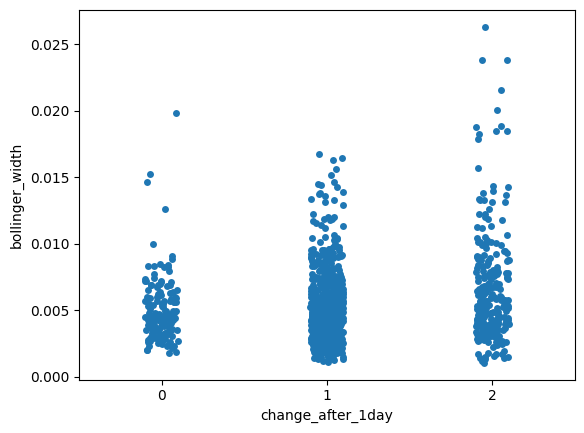

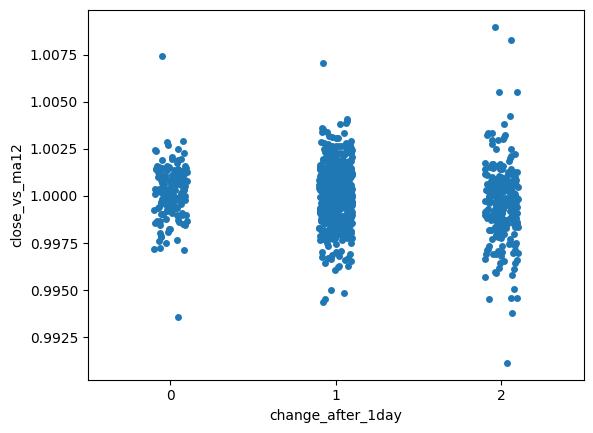

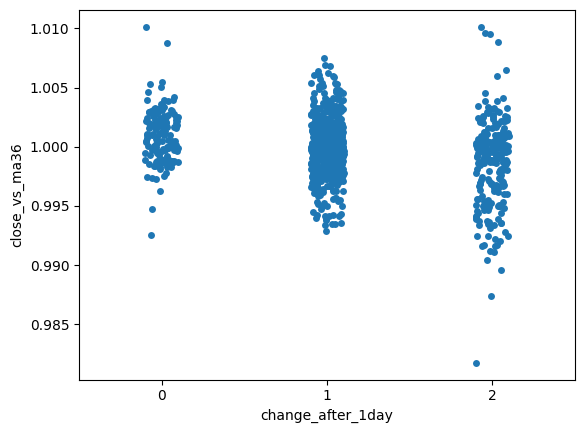

In [11]:
# 분포 
import seaborn as sns
import matplotlib.pyplot as plt

# 전처리
# cv_ai_trainer.load_model_config(cv_ai_trainer.auto_ml_path)
# df_preprocessed = cv_ai_trainer.preprocess_all(df) = df.copy()

# 예: n 개만 랜덤 추출
df_sample = df.sample(n=1000, random_state=42)  

# change_after_1day를 문자열로 캐스팅 (boxplot의 x축을 이산형으로 인식시키기 위해)
df_sample['change_after_1day'] = df_sample['change_after_1day'].astype(str)

for idx, feature in enumerate(features):
    if idx > 1:
        df_sorted = df_sample.sort_values(by=feature, ascending=False)
        sns.stripplot(x='change_after_1day', y=feature, data=df_sorted, order=['0', '1', '2'])
        plt.show()


(10181, 92)
(10181,)


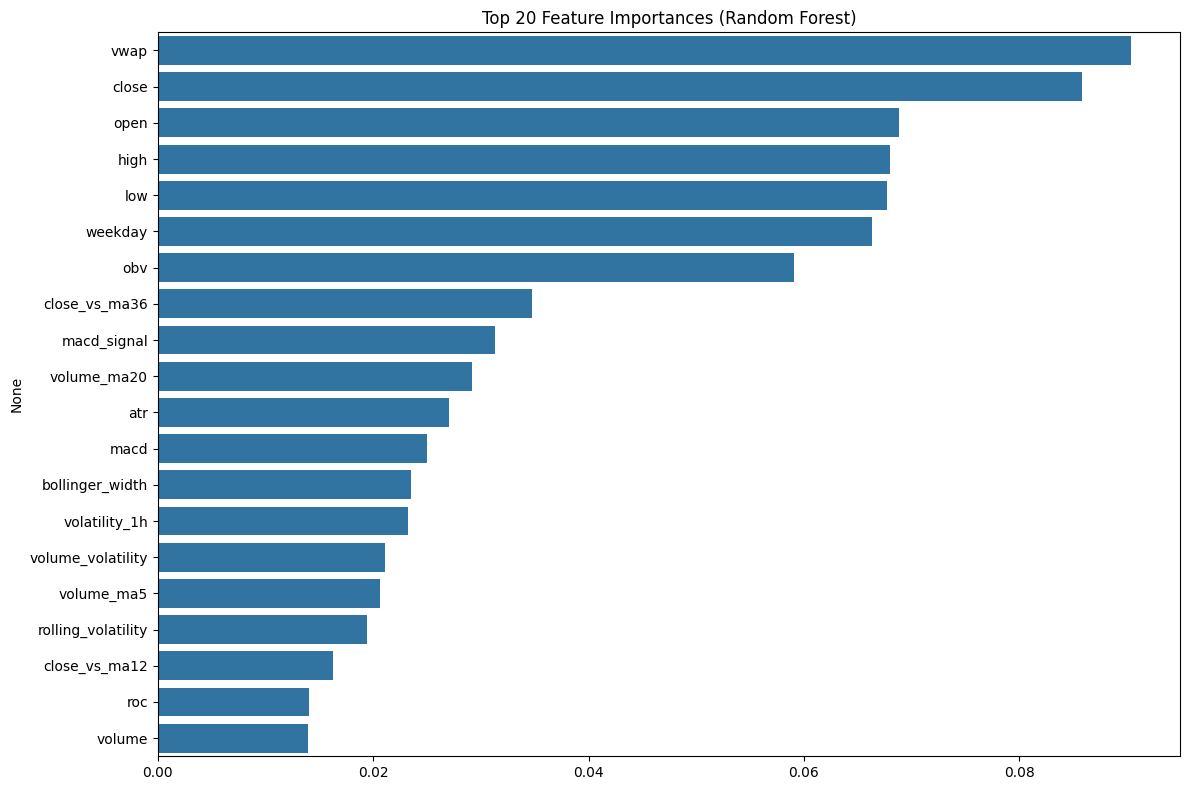

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

df.fillna(df.mean(numeric_only=True), inplace=True)

# 1. 숫자형 피처만 선택
X = df[features]
y = df['change_after_1day']


#
X = X.select_dtypes(exclude=['datetime'])

# 2. 학습/검증 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. 모델 훈련
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 4. Feature Importance 추출
importances = model.feature_importances_
feature_importance = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

# 5. 시각화
plt.figure(figsize=(12, 8))
sns.barplot(x=feature_importance.values[:20], y=feature_importance.index[:20])
plt.title('Top 20 Feature Importances (Random Forest)')
plt.tight_layout()
plt.show()